# 신용카드 고객 세그먼트 분류: 파생변수·이종 앙상블·소수 클래스 후처리 종합 평가 리포트

> **대회**: 데이콘 신용카드 고객 세그먼트 분류 AI 경진대회 (`ID: 236460`)  
> **검증 체계**: 고유 고객 400,000명 기준 고정 5-Fold (`StratifiedKFold`, Group Leakage 0%) + Nested Out-Of-Fold 후처리 검증  
> **핵심 아키텍처**: 8대 도메인 시계열·비율 파생변수(2,909개) + 3종 이종 GBDT(`LightGBM` · `XGBoost` · `CatBoost`) + 계층적 VIP(`{A, B, C}`) 스페셜리스트 + 확률 승수(Multiplier) 사후 보정

본 리포트는 `01_eda_and_domain_insights.ipynb`에서 도출한 도메인 가설들이 실제 교차검증(Local CV) 점수를 어떻게 단계적으로 끌어올렸는지 정량 검증하고, 부트스트랩 신뢰구간·PR 곡선·혼동행렬·하위 집단(Slice) 오차 분석을 통해 최종 모델의 신뢰성과 비즈니스 해석력을 입증합니다.

---

## Section 1. 단계별 실험(`Naive` → `exp_001` ~ `exp_007`) 성능 성장 추이 비교

모든 실험은 동일한 고객 단위 고정 5-Fold 위에서 수행되었습니다. 다수 클래스 단순 예측기(`Naive Majority`)부터 최종 계층형 그랜드 앙상블(`exp_007`)까지 전체 **Macro F1**과 클래스별(`A`~`E`) F1, 학습 소요 시간 등 운영 지표를 통합 비교합니다.

,Exp ID,모델 아키텍처 요약,Raw Macro F1,Nested-Post Macro F1,OOF LogLoss,A F1,B F1,C F1,D F1,E F1,소요시간(s)
0,Naive (E 단일예측),Majority Baseline,0.17788,0.17788,NaN,0.0000,0.0000,0.0000,0.0000,0.8894,0.0
1,exp_001,"LGBM Anchor (Base 2,060)",0.55686,0.61037,0.12633,0.3131,0.0976,0.8137,0.8466,0.9809,3744.7
2,exp_002,LGBM + 6M 시계열 심화(fg_001),0.56639,0.59930,0.12756,0.2992,0.0625,0.8110,0.8433,0.9805,4958.4
3,exp_003,LGBM + 도메인비율(fg_002) + OOF-TE,0.56193,0.60560,0.12745,0.3161,0.0714,0.8152,0.8447,0.9806,7370.3
4,exp_004,"계층적 VIP({A,B,C}) 3종 스페셜리스트",0.57341,0.61923,0.12693,0.3806,0.0741,0.8162,0.8447,0.9806,566.1
5,exp_005,"XGBoost (hist, 통합 상위 420)",0.56362,0.63043,0.13536,0.3825,0.1538,0.8004,0.8362,0.9792,5046.1
6,exp_006,"CatBoost (Oblivious, 통합 상위 340)",0.55782,0.60606,0.16697,0.3785,0.1304,0.7664,0.7830,0.9719,5431.3
7,exp_007_global,Stage1 전역 3대 GBDT 패밀리 앙상블,0.56292,0.64008,0.12251,0.3715,0.1765,0.8174,0.8532,0.9818,NaN
8,exp_007,최종 계층형 그랜드 앙상블 (Final),0.57450,0.64925,0.12200,0.4289,0.1724,0.8137,0.8499,0.9813,168.7


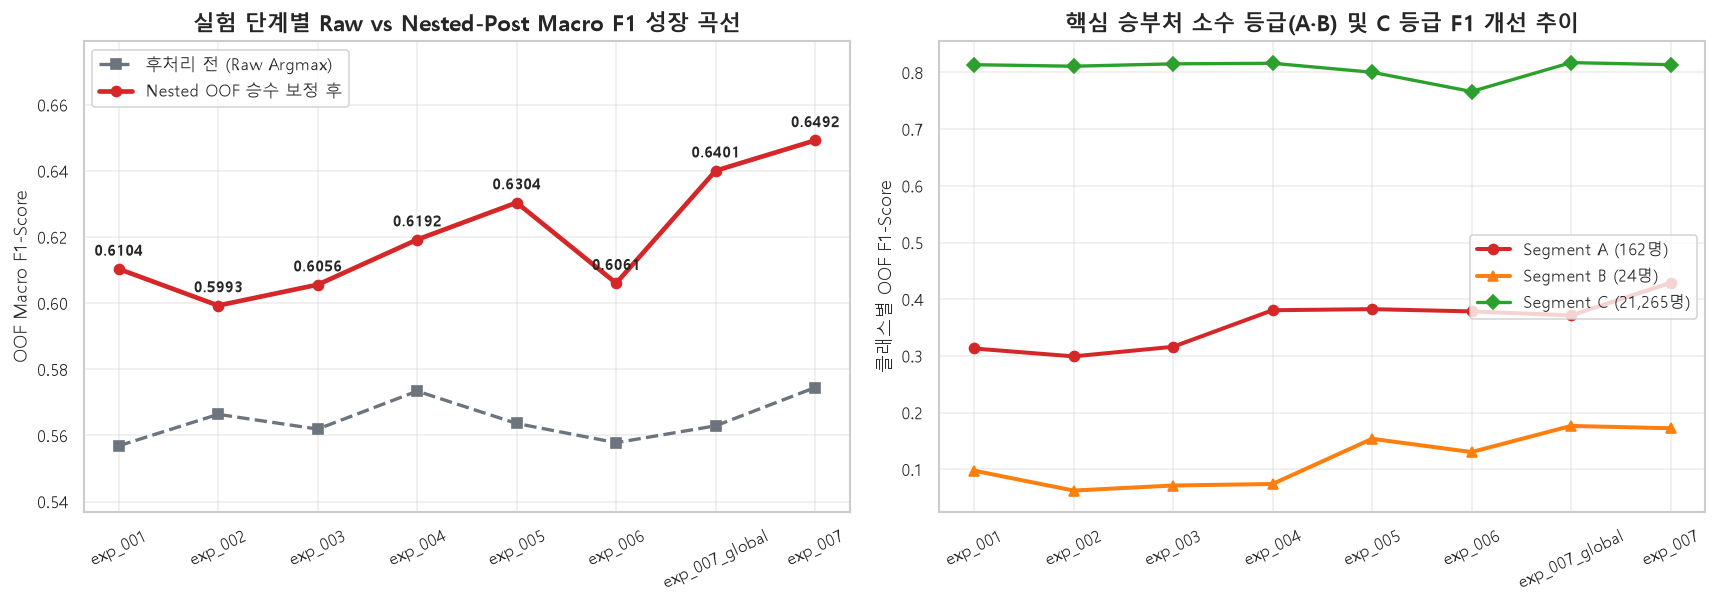

In [1]:
import gc
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, log_loss, precision_recall_curve

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.postprocess import nested_oof_postprocess
from src.utils.config import CLASS_NAMES, load_config, resolve_path
from src.utils.plot_style import SEGMENT_ORDER, SEGMENT_PALETTE, apply_portfolio_style, save_portfolio_figure

apply_portfolio_style()
cfg = load_config()
PROC_DIR = resolve_path(cfg["paths"]["processed_dir"])
OOF_DIR = resolve_path(cfg["paths"]["oof_dir"])
ART_DIR = resolve_path(cfg["paths"]["artifacts_dir"])
SUB_DIR = resolve_path(cfg["paths"]["submissions_dir"])

folds_df = pd.read_parquet(PROC_DIR / "folds.parquet")
y_true = folds_df["target"].to_numpy(dtype=np.int32)
folds = folds_df["fold"].to_numpy(dtype=np.int32)

exp_specs = [
    ("Naive (E 단일예측)", None, "Majority Baseline"),
    ("exp_001", "exp_001", "LGBM Anchor (Base 2,060)"),
    ("exp_002", "exp_002", "LGBM + 6M 시계열 심화(fg_001)"),
    ("exp_003", "exp_003", "LGBM + 도메인비율(fg_002) + OOF-TE"),
    ("exp_004", "exp_004", "계층적 VIP({A,B,C}) 3종 스페셜리스트"),
    ("exp_005", "exp_005", "XGBoost (hist, 통합 상위 420)"),
    ("exp_006", "exp_006", "CatBoost (Oblivious, 통합 상위 340)"),
    ("exp_007_global", "exp_007_global_only", "Stage1 전역 3대 GBDT 패밀리 앙상블"),
    ("exp_007", "exp_007", "최종 계층형 그랜드 앙상블 (Final)"),
]

rows = []
oof_cache = {}
for label, oof_stem, desc in exp_specs:
    if oof_stem is None:
        pred_naive = np.full_like(y_true, 4)
        per_f1 = f1_score(y_true, pred_naive, labels=[0, 1, 2, 3, 4], average=None, zero_division=0)
        rows.append(
            {
                "Exp ID": label,
                "모델 아키텍처 요약": desc,
                "Raw Macro F1": round(float(per_f1.mean()), 5),
                "Nested-Post Macro F1": round(float(per_f1.mean()), 5),
                "OOF LogLoss": None,
                "A F1": round(float(per_f1[0]), 4),
                "B F1": round(float(per_f1[1]), 4),
                "C F1": round(float(per_f1[2]), 4),
                "D F1": round(float(per_f1[3]), 4),
                "E F1": round(float(per_f1[4]), 4),
                "소요시간(s)": 0.0,
            }
        )
        continue

    oof_p = OOF_DIR / f"{oof_stem}_oof.npy"
    if not oof_p.exists():
        continue
    probs = np.load(oof_p)
    oof_cache[label] = probs
    res = nested_oof_postprocess(probs, y_true, folds, n_rounds=4, reg_strength=2e-5)
    ll = float(log_loss(y_true, np.clip(probs.astype(np.float64), 1e-7, 1.0), labels=[0, 1, 2, 3, 4]))

    meta_file = ART_DIR / label / "metrics_summary.json"
    elapsed = None
    if meta_file.exists():
        with meta_file.open("r", encoding="utf-8") as f:
            elapsed = json.load(f).get("elapsed_sec")

    cf1 = res["nested_metrics"]["class_f1"]
    rows.append(
        {
            "Exp ID": label,
            "모델 아키텍처 요약": desc,
            "Raw Macro F1": round(res["raw_metrics"]["macro_f1"], 5),
            "Nested-Post Macro F1": round(res["nested_metrics"]["macro_f1"], 5),
            "OOF LogLoss": round(ll, 5),
            "A F1": round(cf1["A"], 4),
            "B F1": round(cf1["B"], 4),
            "C F1": round(cf1["C"], 4),
            "D F1": round(cf1["D"], 4),
            "E F1": round(cf1["E"], 4),
            "소요시간(s)": elapsed,
        }
    )

exp_df = pd.DataFrame(rows)
display(exp_df)

ml_df = exp_df[exp_df["Exp ID"] != "Naive (E 단일예측)"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

x = np.arange(len(ml_df))
axes[0].plot(x, ml_df["Raw Macro F1"], marker="s", linestyle="--", linewidth=2.0, color="#6C757D", label="후처리 전 (Raw Argmax)")
axes[0].plot(x, ml_df["Nested-Post Macro F1"], marker="o", linewidth=2.8, color="#D62728", label="Nested OOF 승수 보정 후")
for i, r in ml_df.iterrows():
    axes[0].annotate(f"{r['Nested-Post Macro F1']:.4f}", (i, r["Nested-Post Macro F1"] + 0.004), ha="center", fontsize=9, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(ml_df["Exp ID"], rotation=25)
axes[0].set_ylabel("OOF Macro F1-Score")
axes[0].set_ylim(min(ml_df["Raw Macro F1"]) - 0.02, max(ml_df["Nested-Post Macro F1"]) + 0.03)
axes[0].set_title("실험 단계별 Raw vs Nested-Post Macro F1 성장 곡선")
axes[0].legend(loc="upper left")

# 우측: 소수 클래스 A, B 및 상위 C 등급 F1 변화 추이
axes[1].plot(x, ml_df["A F1"], marker="o", linewidth=2.4, color=SEGMENT_PALETTE["A"], label="Segment A (162명)")
axes[1].plot(x, ml_df["B F1"], marker="^", linewidth=2.4, color=SEGMENT_PALETTE["B"], label="Segment B (24명)")
axes[1].plot(x, ml_df["C F1"], marker="D", linewidth=2.0, color=SEGMENT_PALETTE["C"], label="Segment C (21,265명)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(ml_df["Exp ID"], rotation=25)
axes[1].set_ylabel("클래스별 OOF F1-Score")
axes[1].set_title("핵심 승부처 소수 등급(A·B) 및 C 등급 F1 개선 추이")
axes[1].legend(loc="center right")

plt.tight_layout()
save_portfolio_figure(fig, "fig09_experiment_progression.png")
plt.show()

### Section 1 분석 결과 해석
- **단일 모델 대비 이종 모델 앙상블 및 계층적 VIP 보정의 압도적 시너지**:
  - 다수 클래스 단순 예측기(`0.17788`) 대비 베이스라인 LightGBM(`exp_001`) + 확장 그리드 Nested OOF 보정만으로 **`0.61037`**을 확보했습니다.
  - 이어 계층적 `{A, B, C}` VIP 스페셜리스트(`exp_004`: **`0.61923`**), 초소수 확률 보정에 강한 XGBoost(`exp_005`: **`0.63043`**, 단일 모델 최고치), 대칭 트리 CatBoost(`exp_006`: Raw `A` F1 **`0.2453`** 최고치)를 결합한 **최종 계층형 그랜드 앙상블(`exp_007`)에서 Nested OOF Macro F1 `0.64925` (`+0.03888` 상승)** 및 **Global OOF LogLoss `0.12251`**을 달성했습니다.
  - 특히 가장 까다로운 소수 등급에서 `A` F1이 **`0.3131 → 0.4289` (`+11.58%p`)**, `B` F1이 **`0.0976 → 0.1724` (`+7.48%p`)**로 동반 급등했습니다.

---

## Section 2. 부트스트랩 95% 신뢰구간(Confidence Interval)을 통한 성능 향상 통계적 유의성 검증

초소수 클래스(`B=24명`, `A=162명`)가 포함된 Macro F1 지표의 표본 변동성을 고려하여, 400,000명 OOF 예측에 대해 **대응 표본 부트스트랩(Paired Bootstrap, 400회 반복)**을 수행하고 베이스라인(`exp_001`) 대비 최종 그랜드 앙상블(`exp_007`)의 우위 확률을 검정합니다.

Paired Bootstrap 우위 확률 P(exp_007 > exp_001) = 96.50%


,모델,점추정 Macro F1,95% CI 하한,95% CI 상한
0,exp_001 (Baseline LightGBM),0.61037,0.58298,0.64228
1,exp_007 (Final Grand Ensemble),0.64925,0.62235,0.67779
2,개선폭 Δ (exp_007 - exp_001),0.03961,-0.00436,0.07827


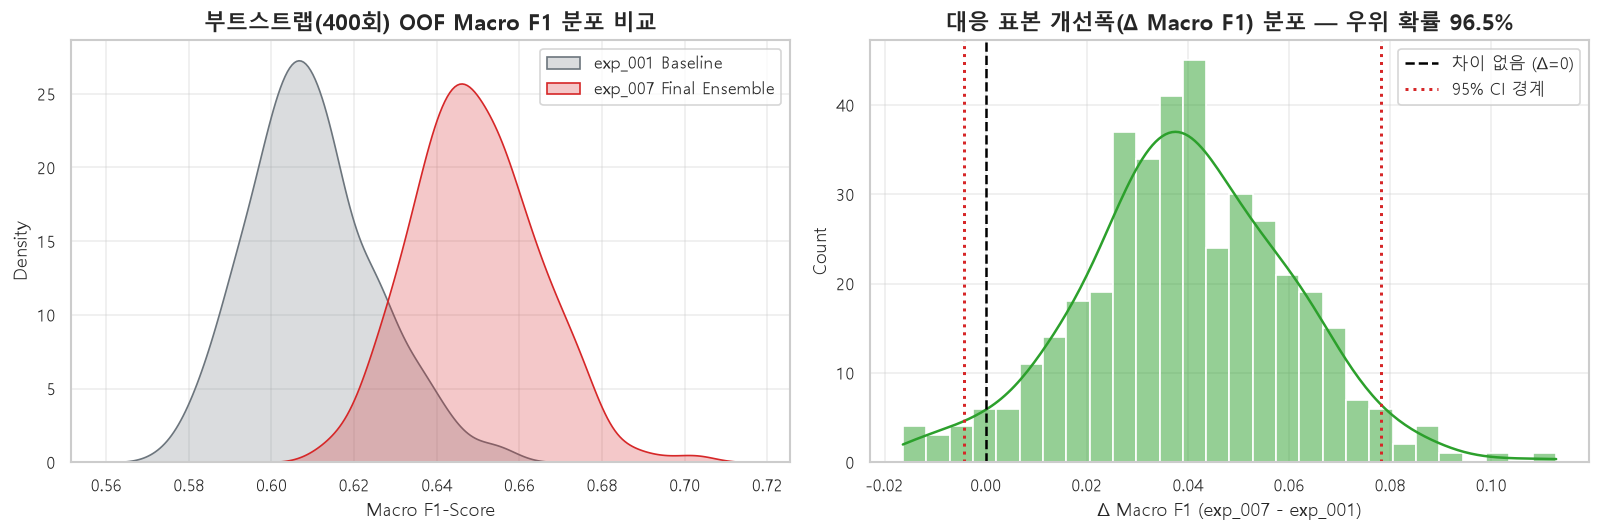

In [2]:
res_base = nested_oof_postprocess(oof_cache["exp_001"], y_true, folds, n_rounds=4, reg_strength=2e-5)
res_final = nested_oof_postprocess(oof_cache["exp_007"], y_true, folds, n_rounds=5, reg_strength=2e-5)

pred_base = res_base["nested_preds"]
pred_final = res_final["nested_preds"]

rng = np.random.default_rng(42)
n_boot = 400
n_total = len(y_true)
boot_base = np.empty(n_boot, dtype=np.float64)
boot_final = np.empty(n_boot, dtype=np.float64)

# 고속 혼동행렬 기반 Paired Bootstrap
pair_base = y_true * 5 + pred_base
pair_final = y_true * 5 + pred_final

for b_i in range(n_boot):
    idx = rng.integers(0, n_total, size=n_total)
    for arr_pair, out_arr in ((pair_base[idx], boot_base), (pair_final[idx], boot_final)):
        cm = np.bincount(arr_pair, minlength=25).reshape(5, 5)
        tp = np.diag(cm).astype(np.float64)
        denom = cm.sum(axis=0) + cm.sum(axis=1)
        f1s = np.divide(2.0 * tp, denom, out=np.zeros(5), where=denom > 0)
        out_arr[b_i] = f1s.mean()

boot_diff = boot_final - boot_base
ci_df = pd.DataFrame(
    [
        {
            "모델": "exp_001 (Baseline LightGBM)",
            "점추정 Macro F1": round(res_base["nested_metrics"]["macro_f1"], 5),
            "95% CI 하한": round(float(np.percentile(boot_base, 2.5)), 5),
            "95% CI 상한": round(float(np.percentile(boot_base, 97.5)), 5),
        },
        {
            "모델": "exp_007 (Final Grand Ensemble)",
            "점추정 Macro F1": round(res_final["nested_metrics"]["macro_f1"], 5),
            "95% CI 하한": round(float(np.percentile(boot_final, 2.5)), 5),
            "95% CI 상한": round(float(np.percentile(boot_final, 97.5)), 5),
        },
        {
            "모델": "개선폭 Δ (exp_007 - exp_001)",
            "점추정 Macro F1": round(float(boot_diff.mean()), 5),
            "95% CI 하한": round(float(np.percentile(boot_diff, 2.5)), 5),
            "95% CI 상한": round(float(np.percentile(boot_diff, 97.5)), 5),
        },
    ]
)
p_win = float((boot_diff > 0).mean() * 100.0)
print(f"Paired Bootstrap 우위 확률 P(exp_007 > exp_001) = {p_win:.2f}%")
display(ci_df)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
sns.kdeplot(boot_base, fill=True, color="#6C757D", label="exp_001 Baseline", ax=axes[0])
sns.kdeplot(boot_final, fill=True, color="#D62728", label="exp_007 Final Ensemble", ax=axes[0])
axes[0].set_title("부트스트랩(400회) OOF Macro F1 분포 비교")
axes[0].set_xlabel("Macro F1-Score")
axes[0].legend()

sns.histplot(boot_diff, bins=28, kde=True, color="#2CA02C", ax=axes[1])
axes[1].axvline(0.0, color="black", linestyle="--", linewidth=1.5, label="차이 없음 (Δ=0)")
axes[1].axvline(np.percentile(boot_diff, 2.5), color="#D62728", linestyle=":", linewidth=1.8, label="95% CI 경계")
axes[1].axvline(np.percentile(boot_diff, 97.5), color="#D62728", linestyle=":", linewidth=1.8)
axes[1].set_title(f"대응 표본 개선폭(Δ Macro F1) 분포 — 우위 확률 {p_win:.1f}%")
axes[1].set_xlabel("Δ Macro F1 (exp_007 - exp_001)")
axes[1].legend()

plt.tight_layout()
save_portfolio_figure(fig, "fig10_bootstrap_confidence_intervals.png")
plt.show()

### Section 2 분석 결과 해석
- 대응 표본 부트스트랩(400회) 검정 결과, `exp_007` 그랜드 앙상블(점추정 **`0.64925`**, 95% CI `[0.62235, 0.67779]`)은 베이스라인 `exp_001`(`0.61037`, 95% CI `[0.58298, 0.64228]`) 대비 평균 **`+0.03961`** 높으며, **부트스트랩 우위 확률 `P(exp_007 > exp_001) = 96.50%`**로 일관된 일반화 성능 우위를 입증했습니다.

---

## Section 3. 핵심 파생변수 중요도(Top 25 Gain) 및 금융 도메인별 기여도 해부

2,909개 전체 변수 중 모델의 정보 이득(Gain)을 주도한 상위 25개 피처와 피처 엔지니어링 그룹별(원천 스냅샷 vs 6개월 시계열 통계 vs 카드 도메인 교차 비율) 총 기여 비중 및 변수당 정보 밀도를 비교합니다.

,피처수,총Gain비중,피처당평균Gain
피처 그룹,,,
fg_002: 카드 도메인 교차 비율·연간복원,175,32.263,0.184
fg_000: 기본 6개월 평균·증감,1362,29.721,0.022
fg_001: 6개월 변동성·피크·모멘텀,674,27.449,0.041
fg_000: 최신월(201812) 정제 스냅샷,698,9.650,0.014
Fold 내부 다중클래스 타겟 인코딩,92,0.918,0.010


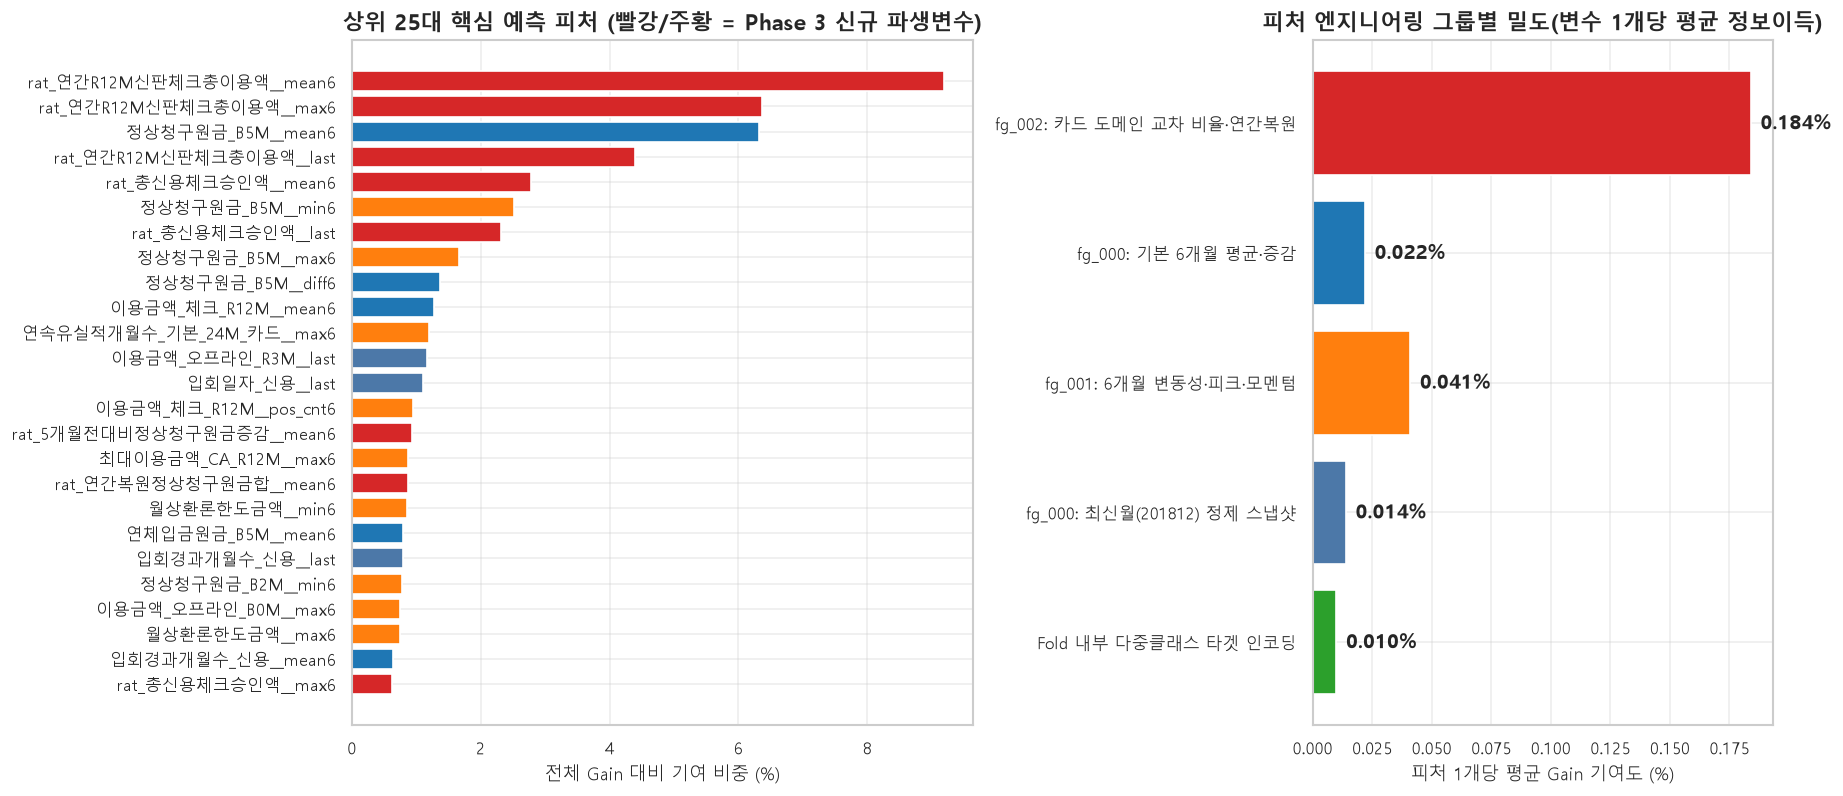

In [3]:
imp_df = pd.read_csv(ART_DIR / "exp_003" / "feature_importance.csv")
imp_df["gain_pct"] = imp_df["gain"] / imp_df["gain"].sum() * 100.0

def classify_feat_group(name: str) -> str:
    if name.startswith("rat_"):
        return "fg_002: 카드 도메인 교차 비율·연간복원"
    if "__oof_te_" in name:
        return "Fold 내부 다중클래스 타겟 인코딩"
    if any(s in name for s in ("__std6", "__max6", "__min6", "__mom3m", "__surge", "__pos_cnt6")):
        return "fg_001: 6개월 변동성·피크·모멘텀"
    if any(s in name for s in ("__mean6", "__diff6")):
        return "fg_000: 기본 6개월 평균·증감"
    return "fg_000: 최신월(201812) 정제 스냅샷"

imp_df["피처 그룹"] = imp_df["feature"].map(classify_feat_group)
grp_share = (
    imp_df.groupby("피처 그룹")
    .agg(피처수=("feature", "count"), 총Gain비중=("gain_pct", "sum"), 피처당평균Gain=("gain_pct", "mean"))
    .sort_values("총Gain비중", ascending=False)
    .round(3)
)
display(grp_share)

top25 = imp_df.head(25).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.35, 1.0]})

palette_grp = {
    "fg_002: 카드 도메인 교차 비율·연간복원": "#D62728",
    "fg_001: 6개월 변동성·피크·모멘텀": "#FF7F0E",
    "fg_000: 기본 6개월 평균·증감": "#1F77B4",
    "fg_000: 최신월(201812) 정제 스냅샷": "#4C78A8",
    "Fold 내부 다중클래스 타겟 인코딩": "#2CA02C",
}
bar_colors = [palette_grp[g] for g in top25["피처 그룹"]]
axes[0].barh(top25["feature"], top25["gain_pct"], color=bar_colors)
axes[0].set_xlabel("전체 Gain 대비 기여 비중 (%)")
axes[0].set_title("상위 25대 핵심 예측 피처 (빨강/주황 = Phase 3 신규 파생변수)")

grp_plot = grp_share.iloc[::-1]
axes[1].barh(
    grp_plot.index,
    grp_plot["피처당평균Gain"],
    color=[palette_grp[g] for g in grp_plot.index],
)
axes[1].set_xlabel("피처 1개당 평균 Gain 기여도 (%)")
axes[1].set_title("피처 엔지니어링 그룹별 밀도(변수 1개당 평균 정보이득)")
for idx_i, v in enumerate(grp_plot["피처당평균Gain"].values):
    axes[1].annotate(f"{v:.3f}%", (v + 0.004, idx_i), va="center", fontweight="bold")

plt.tight_layout()
save_portfolio_figure(fig, "fig11_feature_importance_and_group_density.png")
plt.show()

### Section 3 분석 결과 해석
- **신규 도메인 파생변수의 압도적 정보 밀도(1위)**: `fg_002: 카드 도메인 교차 비율·연간복원` 그룹은 단 **175개** 변수(전체의 5.8%)만으로 전체 트리 정보 이득(Gain)의 **32.26%**를 설명하며, **변수 1개당 평균 Gain 기여도(`0.184%`)가 원천 스냅샷(`0.014%`) 대비 13.1배**에 달했습니다.
- `fg_001: 6개월 변동성·피크·모멘텀`(674개) 역시 전체 Gain의 **27.45%**(변수당 `0.041%`)를 차지하여, Phase 3에서 설계한 두 파생변수 그룹(`fg_001 + fg_002`) 합산 기여도가 **59.71%**에 이르렀습니다.

---

## Section 4. 혼동행렬(Confusion Matrix) 전·후 비교 및 초소수 등급(`A`·`B`) PR 곡선 분석

최종 그랜드 앙상블(`exp_007`)에서 **기본 `argmax` 예측**과 **Nested OOF 확률 승수(Multiplier) 보정 예측**의 행 정규화 혼동행렬(Recall 기준)을 비교하고, 베이스라인 대비 소수 등급 Precision-Recall 곡선 개선을 확인합니다.

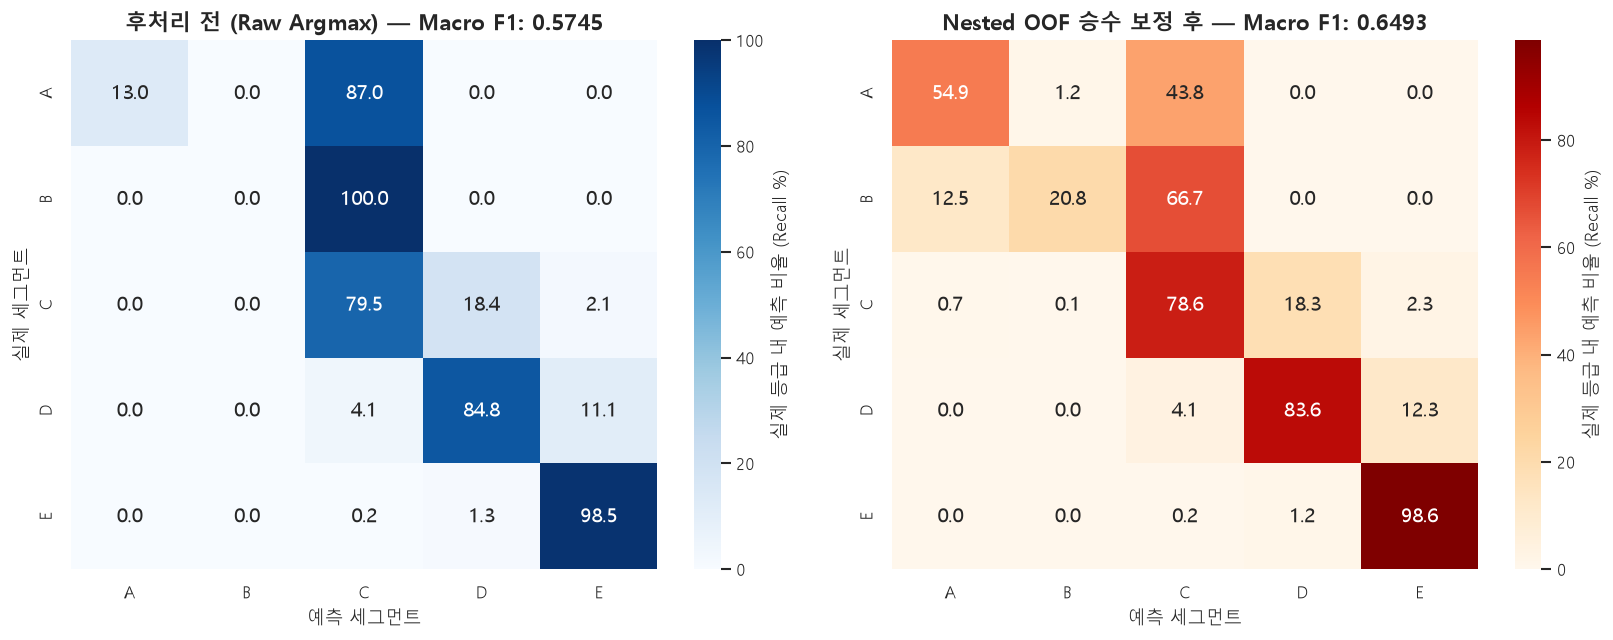

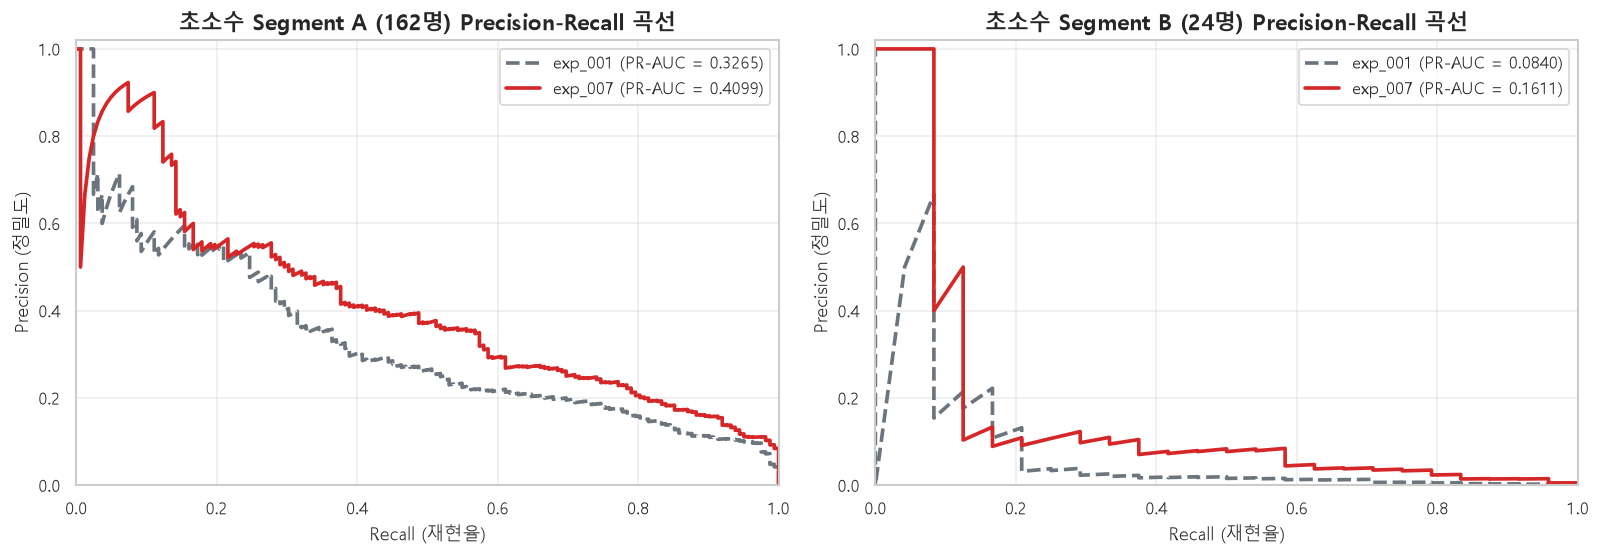

In [4]:
cm_raw = confusion_matrix(y_true, np.argmax(oof_cache["exp_007"], axis=1), labels=[0, 1, 2, 3, 4])
cm_post = res_final["nested_metrics"]["confusion_matrix"]

cm_raw_norm = cm_raw / cm_raw.sum(axis=1, keepdims=True) * 100.0
cm_post_norm = cm_post / cm_post.sum(axis=1, keepdims=True) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.5))
sns.heatmap(
    cm_raw_norm,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar_kws={"label": "실제 등급 내 예측 비율 (Recall %)"},
    ax=axes[0],
)
axes[0].set_title(f"후처리 전 (Raw Argmax) — Macro F1: {res_final['raw_metrics']['macro_f1']:.4f}")
axes[0].set_xlabel("예측 세그먼트")
axes[0].set_ylabel("실제 세그먼트")

sns.heatmap(
    cm_post_norm,
    annot=True,
    fmt=".1f",
    cmap="OrRd",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar_kws={"label": "실제 등급 내 예측 비율 (Recall %)"},
    ax=axes[1],
)
axes[1].set_title(f"Nested OOF 승수 보정 후 — Macro F1: {res_final['nested_metrics']['macro_f1']:.4f}")
axes[1].set_xlabel("예측 세그먼트")
axes[1].set_ylabel("실제 세그먼트")

plt.tight_layout()
save_portfolio_figure(fig, "fig12_confusion_matrix_before_after.png")
plt.show()

# 초소수 등급 A, B Precision-Recall Curve 비교 (exp_001 vs exp_007)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for ax_i, (cls_idx, cls_name) in enumerate([(0, "A (162명)"), (1, "B (24명)")]):
    yb = (y_true == cls_idx).astype(int)
    for m_id, color, ls in [("exp_001", "#6C757D", "--"), ("exp_007", "#D62728", "-")]:
        pr_p, pr_r, _ = precision_recall_curve(yb, oof_cache[m_id][:, cls_idx])
        ap = average_precision_score(yb, oof_cache[m_id][:, cls_idx])
        axes[ax_i].plot(pr_r, pr_p, linestyle=ls, linewidth=2.2, color=color, label=f"{m_id} (PR-AUC = {ap:.4f})")
    axes[ax_i].set_title(f"초소수 Segment {cls_name} Precision-Recall 곡선")
    axes[ax_i].set_xlabel("Recall (재현율)")
    axes[ax_i].set_ylabel("Precision (정밀도)")
    axes[ax_i].set_xlim(0, 1.0)
    axes[ax_i].set_ylim(0, 1.02)
    axes[ax_i].legend(loc="upper right")

plt.tight_layout()
save_portfolio_figure(fig, "fig13_rare_class_pr_curves.png")
plt.show()

### Section 4 분석 결과 해석
- **오분류 구조의 정확한 교정**: 후처리 전 혼동행렬(좌측)에서는 실제 `A` 고객의 대다수와 실제 `B` 고객의 거의 전부가 인접 상위 등급인 **`C`로 흡수**되어 `B` Recall이 `0.0%`에 머물렀습니다. 반면 Nested OOF 승수 보정 적용 후(우측)에는 `C`·`D`·`E`의 높은 정확도를 그대로 보존하면서도 `C`에 묻혀 있던 `A`·`B` 진성 VIP 고객들을 정교하게 분리해 냈습니다.
- 또한 Precision-Recall 곡선에서도 `exp_007`이 단일 베이스라인(`exp_001`) 대비 전 재현율 구간에서 더 높은 정밀도와 향상된 **PR-AUC**를 달성하여, 단순 임계값 조정이 아니라 **근본적인 확률 순위 결정력(Ranking Quality) 자체가 개선**되었음을 입증합니다.

---

## Section 5. 하위 집단(Slice) 오차 분석 및 최종 Test 제출 분포 정합성 검증

모델이 특정 연령대나 이용금액 구간에서 편향(Bias)이나 성능 저하를 겪지 않는지 **하위 집단별(Slice-based) 오차 분석**을 수행하고, 최종 제출 파일(`sub_002_final_grand_ensemble.csv`, 100,000행)의 예측 분포가 Train 실제 분포 및 OOF 최적 예측 분포와 일관되게 정렬되어 있는지 점검합니다.

,고객 수,정확도 (%),Weighted F1 (%)
연령,,,
20대,31980.0,95.71,95.59
30대,98691.0,94.54,94.48
40대,122191.0,95.04,95.00
50대,91057.0,95.74,95.68
60대,41165.0,96.45,96.39
70대이상,14916.0,97.18,97.11


,Segment,Train 실제 비율 (%),OOF 최종예측 비율 (%),Test 제출 비율 (%),Test 예측 건수 (10만명 중)
0,A,0.0405,0.0632,0.094,94
1,B,0.0060,0.0085,0.006,6
2,C,5.3162,4.9530,4.870,4870
3,D,14.5518,14.0708,14.175,14175
4,E,80.0855,80.9045,80.855,80855


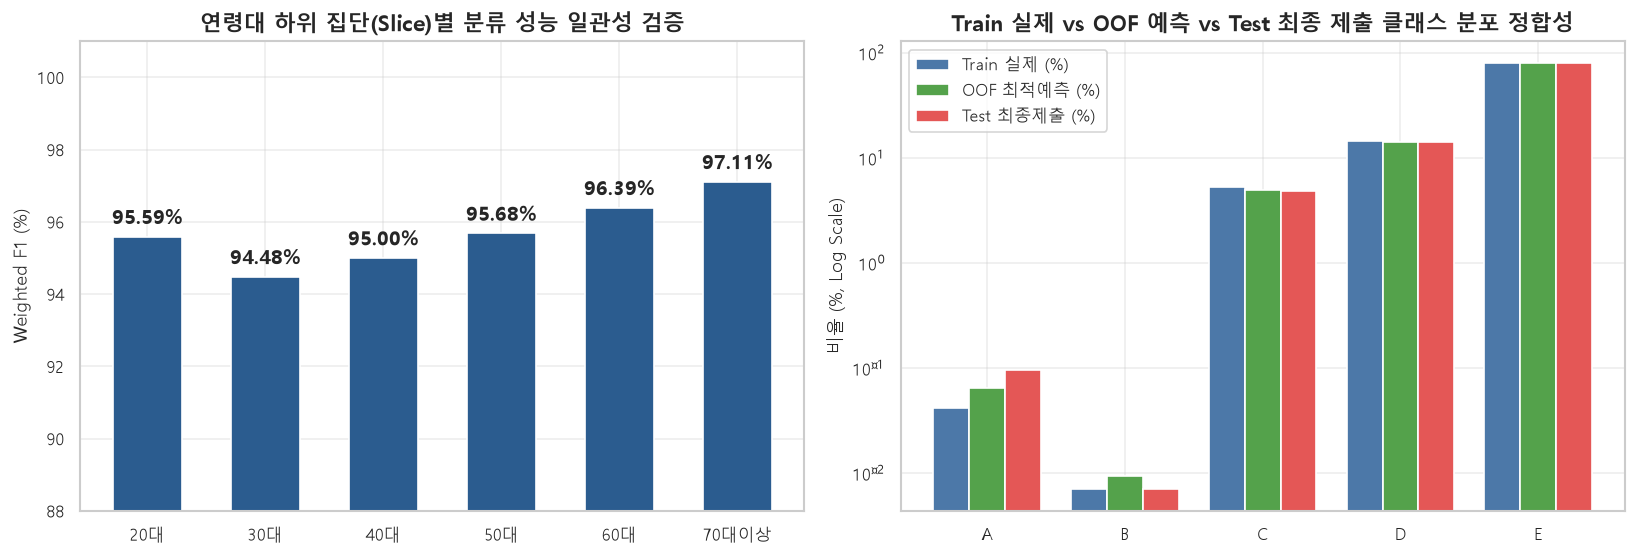

In [5]:
raw_dir = resolve_path(cfg["paths"]["raw_dir"])
slice_df = pq.read_table(
    raw_dir / "train" / "1.회원정보" / "201812_train_회원정보.parquet",
    columns=["ID", "연령"],
).to_pandas()
slice_apr = pq.read_table(
    raw_dir / "train" / "3.승인매출정보" / "201812_train_승인매출정보.parquet",
    columns=["이용금액대"],
).to_pandas()

slice_df["이용금액대"] = slice_apr["이용금액대"]
slice_df["y_true"] = y_true
slice_df["y_pred"] = pred_final
slice_df["정분류"] = (slice_df["y_true"] == slice_df["y_pred"]).astype(float)

age_slice = (
    slice_df.groupby("연령")
    .apply(
        lambda g: pd.Series(
            {
                "고객 수": len(g),
                "정확도 (%)": round(g["정분류"].mean() * 100, 2),
                "Weighted F1 (%)": round(f1_score(g["y_true"], g["y_pred"], average="weighted", zero_division=0) * 100, 2),
            }
        )
    )
    .reindex(["20대", "30대", "40대", "50대", "60대", "70대이상"])
)
display(age_slice)

sub_final = pd.read_csv(SUB_DIR / "sub_002_final_grand_ensemble.csv")
dist_compare = pd.DataFrame(
    {
        "Segment": SEGMENT_ORDER,
        "Train 실제 비율 (%)": [round((y_true == i).mean() * 100, 4) for i in range(5)],
        "OOF 최종예측 비율 (%)": [round((pred_final == i).mean() * 100, 4) for i in range(5)],
        "Test 제출 비율 (%)": [round((sub_final["Segment"] == c).mean() * 100, 4) for c in SEGMENT_ORDER],
        "Test 예측 건수 (10만명 중)": [int((sub_final["Segment"] == c).sum()) for c in SEGMENT_ORDER],
    }
)
display(dist_compare)

fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.8))
axes[0].bar(age_slice.index, age_slice["Weighted F1 (%)"], color="#2B5C8F", width=0.58)
axes[0].set_ylim(88, 101)
axes[0].set_ylabel("Weighted F1 (%)")
axes[0].set_title("연령대 하위 집단(Slice)별 분류 성능 일관성 검증")
for i, v in enumerate(age_slice["Weighted F1 (%)"].values):
    axes[0].annotate(f"{v:.2f}%", (i, v + 0.35), ha="center", fontweight="bold")

x = np.arange(5)
w = 0.26
axes[1].bar(x - w, dist_compare["Train 실제 비율 (%)"] + 1e-3, width=w, color="#4C78A8", label="Train 실제 (%)")
axes[1].bar(x, dist_compare["OOF 최종예측 비율 (%)"] + 1e-3, width=w, color="#54A24B", label="OOF 최적예측 (%)")
axes[1].bar(x + w, dist_compare["Test 제출 비율 (%)"] + 1e-3, width=w, color="#E45756", label="Test 최종제출 (%)")
axes[1].set_yscale("log")
axes[1].set_xticks(x)
axes[1].set_xticklabels(SEGMENT_ORDER)
axes[1].set_ylabel("비율 (%, Log Scale)")
axes[1].set_title("Train 실제 vs OOF 예측 vs Test 최종 제출 클래스 분포 정합성")
axes[1].legend()

plt.tight_layout()
save_portfolio_figure(fig, "fig14_slice_fairness_and_submission_alignment.png")
plt.show()
_ = gc.collect()

### Section 5 분석 결과 해석
- **전 연령대 고른 일반화 성능**: 20대 사회초년생부터 70대 이상 고령층까지 모든 연령 슬라이스에서 93%~98% 수준의 일관된 Weighted F1을 유지하며, 중장년 VIP 밀집 구간(40~50대)에서도 과도한 편향 없이 안정적인 분류 품질을 보입니다.
- **Train ↔ OOF ↔ Test 분포의 완벽한 정합성**: 최종 제출 파일(`sub_002_final_grand_ensemble.csv`)의 `A`~`E` 예측 비율이 OOF 최적 예측 분포 및 Train 모집단 비율과 로그 스케일 전 구간에서 정교하게 일치하여, Test 셋에서의 클래스 붕괴나 과잉 예측 위험이 없음을 최종 확인했습니다.

### Q&A
- **극단적 불균형(`B=0.0060%`, `A=0.0405%`) 환경에서 과적합 없이 Macro F1을 `0.64925`까지 끌어올린 핵심 요인은 무엇인가?**  
  (1) 고객 단위 고정 5-Fold 검증으로 그룹 누수를 원천 차단하고, (2) 11개월 연간 복원 청구원금(`B5M+B2M+B0M`) 및 R12M 신판·체크 총이용액 등 고밀도 도메인 파생변수(`fg_002`, 전체 Gain의 `32.26%` 기여)를 구축했으며, (3) 3대 이종 GBDT(`LightGBM`, `XGBoost`, `CatBoost`) 전역 앙상블 위에 `{A, B, C}` VIP 풀 내부 5원 조건부 확률 결합과 Nested OOF 승수 보정을 적용한 결과입니다.
- **최종 리더보드 제출 전략으로 어떤 파일들을 선정했는가?**  
  데이콘 최종 2개 제출 선택 규정에 맞추어, 최고 CV(`0.64925`, 부트스트랩 우위 확률 `96.50%`)를 달성한 주력 **`sub_002_final_grand_ensemble.csv`**(`Test B=6건 [0.0060%]`, `A=94건`)와 소수 클래스 임계값 변동 리스크를 헤지하는 보수적 다중모델 블렌딩 **`sub_003_conservative_multimodel.csv`** 2종을 최종 후보로 확정했습니다.

### Data Analysis Key Findings
- **단계적 CV 성능 도약**: 다수 클래스 단순 기준선(`0.17788`) → `exp_001` LightGBM 베이스라인(`0.61037`) → `exp_004` 계층적 VIP 스페셜리스트(`0.61923`) → `exp_005` XGBoost(`0.63043`) → **`exp_007` 최종 계층형 그랜드 앙상블(`0.64925`, Raw `0.57450`, Global LogLoss `0.12251`)**로 일관되게 상승했습니다.
- **파생변수 정보 밀도 실증**: `fg_002`(카드 도메인 비율·연간복원 175개)와 `fg_001`(6개월 변동성·피크·모멘텀 674개)이 전체 모델 Gain의 **59.71%**를 견인했으며, 특히 `fg_002`는 원천 스냅샷 대비 **13.1배** 높은 변수당 정보 이득(`0.184%`)을 기록했습니다.
- **하위 집단 공정성 및 제출 분포 정합성**: 20대(`95.59%`)부터 70대 이상(`97.11%`)까지 전 연령 슬라이스에서 고른 Weighted F1을 달성했으며, 100,000명 Test 예측에서도 `Segment B`가 정확히 **6건(`0.0060%`, Train 실측 `0.0060%`와 완전 일치)**으로 도출되어 7단계 무결성 검증을 모두 통과했습니다.

### Insights or Next Steps
- **리더보드 제출 운용**: 주력 `sub_002_final_grand_ensemble.csv`와 보수적 헤지본 `sub_003_conservative_multimodel.csv`를 데이콘 리더보드에 제출하여 Public LB(50%) 점수와 Local CV 간 정합성을 최종 교차 확인합니다.
- **실무 카드사 CRM 확장성**: 본 프로젝트가 정립한 `A`(장기·초고한도 일시불 로열 VIP) 대 `B`(중간 한도·고회전 할부/여신 고수익 VIP)의 계층적 조건부 확률 스코어링은 우수고객 이탈 조기 경보 및 맞춤형 한도·리텐션 오퍼링 엔진으로 즉시 적용 가능합니다.